# Clasificación de reseñas hoteleras

**Proyectos de Machine Learning · CENESTUR**  
**Integrantes:** Bryan Velastegui, Evelyn Morocho y Erika Gudiño

El problema consiste en clasificar el texto de una reseña como **negativa (0)** o **positiva (1)** para apoyar la revisión de comentarios de huéspedes. El cuaderno reproduce el flujo de la materia: adquirir datos reales, limpiarlos, separar conjuntos por grupos, entrenar, ajustar parámetros, medir el desempeño y guardar el pipeline que utiliza la API.

Se usa [Andalusian Hotels’ Reviews v3](https://www.kaggle.com/datasets/chizhikchi/andalusian-hotels-reviews-unbalanced/versions/3), publicado por Mariia Chizhikova en Kaggle con licencia declarada CC BY-NC 4.0. Las estrellas son una aproximación al sentimiento.

## 1. Entorno y parámetros

Ejecutar de arriba abajo desde la carpeta del proyecto con las dependencias de `requirements.txt`. Para explorar cambios en la rejilla, dejar `EVALUAR_PRUEBA = False`. Los valores incluidos reproducen el experimento de la aplicación.

In [1]:
import csv
import hashlib
import io
import json
import re
import shutil
import tempfile
import unicodedata
from collections import Counter, defaultdict
from importlib.metadata import version
from pathlib import Path
from statistics import mean, stdev

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix
from sklearn.model_selection import ParameterGrid, StratifiedGroupKFold
from sklearn.naive_bayes import ComplementNB
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

BASE = Path.cwd()
DATOS = BASE / "datos"
RESULTADOS = BASE / "resultados"
SOURCE = DATOS / "Big_AHR.csv"
DATASET = "chizhikchi/andalusian-hotels-reviews-unbalanced/3"
SHA256_ORIGINAL = "1eac75de3099cee4d7b688444511a1e26b24c225922518d22410351d1cdf5c39"
SEMILLA = 42
C_LOGISTICA = [0.5, 1.0, 2.0]
ALPHA_NAIVE_BAYES = [0.5, 1.0, 2.0]
EVALUAR_PRUEBA = True
EXPORTAR_MODELO = True
DESTINO_MODELO = RESULTADOS / "modelo"
DESTINO_FIGURAS = RESULTADOS / "figuras_modelo"

for carpeta in (DATOS, RESULTADOS, DESTINO_FIGURAS):
    carpeta.mkdir(parents=True, exist_ok=True)

plt.style.use("seaborn-v0_8-whitegrid")
AZUL = "#234c7c"
TURQUESA = "#0f766e"
NARANJA = "#b9572b"
GRIS = "#687788"


def escribir_json(ruta, datos):
    ruta.write_text(json.dumps(datos, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")


def sha256(ruta):
    return hashlib.sha256(ruta.read_bytes()).hexdigest()


def huella_csv(filas):
    memoria = io.StringIO(newline="")
    escritor = csv.DictWriter(memoria, fieldnames=list(filas[0]))
    escritor.writeheader()
    escritor.writerows(filas)
    return hashlib.sha256(memoria.getvalue().encode("utf-8")).hexdigest()


def mostrar_figura(figura, nombre):
    figura.tight_layout()
    figura.savefig(DESTINO_FIGURAS / f"{nombre}.png", dpi=220, bbox_inches="tight")
    plt.show()
    plt.close(figura)

## 2. Obtener y comprobar el corpus

Se reutiliza `datos/Big_AHR.csv` si su huella coincide con la versión auditada. Cuando el archivo falta, el cliente oficial de Kaggle descarga la versión 3 con las credenciales locales. Se copia únicamente `Big_AHR.csv`. El archivo balanceado comparte textos con el corpus completo y sus positivos se concentran en cinco estrellas.

In [2]:
if not SOURCE.exists() or sha256(SOURCE) != SHA256_ORIGINAL:
    from kaggle.api.kaggle_api_extended import KaggleApi

    api = KaggleApi()
    api.authenticate()
    with tempfile.TemporaryDirectory(prefix="ahr_kaggle_") as directorio:
        api.dataset_download_files(DATASET, path=directorio, unzip=True, quiet=True)
        descargado = Path(directorio) / SOURCE.name
        if sha256(descargado) != SHA256_ORIGINAL:
            raise ValueError("La huella del archivo descargado difiere de la versión auditada")
        shutil.copyfile(descargado, SOURCE)
    escribir_json(DATOS / "descarga_oficial.json", {
        "dataset": DATASET, "cliente": "kaggle", "version_cliente": version("kaggle"),
        "archivo": SOURCE.name, "sha256": sha256(SOURCE),
    })
    print("Corpus descargado con Kaggle y verificado.")
else:
    print("Archivo local verificado contra el SHA-256 de AHR v3.")

with SOURCE.open(encoding="utf-8-sig", newline="") as archivo:
    originales = list(csv.DictReader(archivo))
print(f"Filas originales: {len(originales):,}")

Archivo local verificado contra el SHA-256 de AHR v3.
Filas originales: 18,172


## 3. Limpiar, etiquetar y explorar

Las valoraciones de 1 y 2 estrellas son negativas y las de 4 y 5 son positivas. Se excluyen las de 3 estrellas. Unicode, espacios y mayúsculas se normalizan solo para agrupar duplicados. Se conserva el texto de la primera fila de cada grupo y se verifica la trazabilidad a todas las filas de origen. Solo `review_text` entra al pipeline.

In [3]:
def normalizar(texto):
    return re.sub(r"\s+", " ", unicodedata.normalize("NFC", texto)).strip().casefold()


def preparar(filas):
    grupos = {}
    descartadas = Counter()
    for numero, fila in enumerate(filas, start=2):
        rating = int(fila["rating"])
        esperado = {1: "0", 2: "0", 3: "3", 4: "1", 5: "1"}[rating]
        if fila["label"] != esperado:
            raise ValueError(f"Etiqueta incompatible con estrellas en fila {numero}")
        if rating == 3:
            descartadas["tres_estrellas"] += 1
            continue
        texto = normalizar(fila["review_text"])
        if not texto:
            raise ValueError(f"Texto vacío en fila {numero}")
        grupo = grupos.setdefault(texto, [])
        grupo.append((numero, fila))

    registros = []
    for texto, grupo in grupos.items():
        etiquetas = {fila["label"] for _, fila in grupo}
        if len(etiquetas) != 1:
            raise ValueError("Un mismo texto tiene etiquetas contradictorias")
        primera = grupo[0][1]
        hoteles = sorted({fila["hotel"].strip() for _, fila in grupo if fila["hotel"].strip()})
        registros.append({
            "id": hashlib.sha256(texto.encode()).hexdigest(),
            "title": primera["title"].strip(),
            "review_text": primera["review_text"].strip(),
            "label": primera["label"],
            "sentimiento": "positivo" if primera["label"] == "1" else "negativo",
            "hoteles_json": json.dumps(hoteles, ensure_ascii=False),
            "filas_originales_json": json.dumps([numero for numero, _ in grupo]),
        })
    registros.sort(key=lambda registro: registro["id"])
    return registros, {
        "fuente": DATASET,
        "licencia_declarada": "CC BY-NC 4.0",
        "sha256_original": sha256(SOURCE),
        "sha256_procesado": huella_csv(registros),
        "filas_originales": len(filas),
        "excluidas_tres_estrellas": descartadas["tres_estrellas"],
        "duplicados_binarios_excedentes": sum(len(grupo) - 1 for grupo in grupos.values()),
        "textos_binarios_unicos": len(registros),
        "clases": dict(Counter(fila["sentimiento"] for fila in registros)),
    }


def verificar_limpieza(filas, originales, resumen):
    assert filas, "El conjunto está vacío"
    assert {r["label"] for r in filas} == {"0", "1"}, "Etiquetas no binarias"
    assert len({normalizar(r["review_text"]) for r in filas}) == len(filas), "Textos repetidos"
    assert all(r["review_text"].strip() for r in filas), "Hay textos vacíos"
    fuentes = set()
    for fila in filas:
        texto = normalizar(fila["review_text"])
        assert fila["id"] == hashlib.sha256(texto.encode()).hexdigest(), "ID incompatible"
        assert fila["sentimiento"] == ("positivo" if fila["label"] == "1" else "negativo")
        indices = json.loads(fila["filas_originales_json"])
        assert indices, "Falta trazabilidad"
        for indice in indices:
            assert indice not in fuentes, "Fila original contada dos veces"
            fuentes.add(indice)
            original = originales[indice - 2]
            assert normalizar(original["review_text"]) == texto
            assert original["label"] == fila["label"]
            assert int(original["rating"]) != 3
    esperadas = {i for i, r in enumerate(originales, 2) if int(r["rating"]) != 3}
    assert fuentes == esperadas, "Faltan o sobran filas originales binarias"
    assert resumen["textos_binarios_unicos"] == len(filas)
    assert resumen["clases"] == dict(Counter(r["sentimiento"] for r in filas))

resenas, preparacion = preparar(originales)
verificar_limpieza(resenas, originales, preparacion)
escribir_json(DATOS / "preparacion.json", preparacion)
display(pd.DataFrame({"Etapa": ["Reseñas originales", "Excluidas por tres estrellas",
    "Filas duplicadas retiradas", "Reseñas binarias únicas"], "Cantidad": [
    preparacion["filas_originales"], preparacion["excluidas_tres_estrellas"],
    preparacion["duplicados_binarios_excedentes"], preparacion["textos_binarios_unicos"]]}))

,Etapa,Cantidad
0,Reseñas originales,18172
1,Excluidas por tres estrellas,2274
2,Filas duplicadas retiradas,4308
3,Reseñas binarias únicas,11590


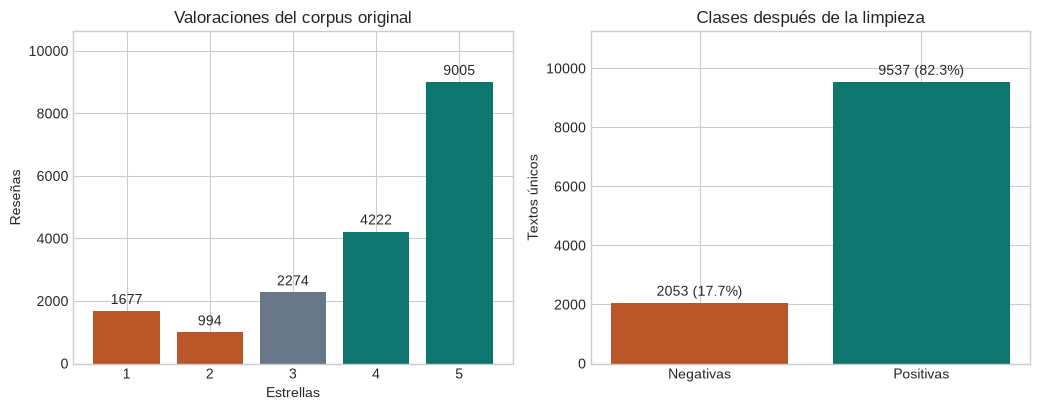

In [4]:
estrellas = Counter(int(fila["rating"]) for fila in originales)
clases = Counter(int(fila["label"]) for fila in resenas)
fig, ejes = plt.subplots(1, 2, figsize=(10.5, 4.2))
barras = ejes[0].bar(range(1, 6), [estrellas[i] for i in range(1, 6)],
                    color=[NARANJA, NARANJA, GRIS, TURQUESA, TURQUESA])
ejes[0].bar_label(barras, padding=3)
ejes[0].set(title="Valoraciones del corpus original", xlabel="Estrellas", ylabel="Reseñas", ylim=(0, max(estrellas.values()) * 1.18))
ejes[0].set_xticks(range(1, 6))
barras = ejes[1].bar(["Negativas", "Positivas"], [clases[0], clases[1]], color=[NARANJA, TURQUESA])
ejes[1].bar_label(barras, [f"{clases[i]} ({clases[i]/len(resenas):.1%})" for i in (0, 1)], padding=3)
ejes[1].set(title="Clases después de la limpieza", ylabel="Textos únicos", ylim=(0, max(clases.values()) * 1.18))
mostrar_figura(fig, "01_distribucion_del_corpus")

## 4. Crear las particiones por grupos

Se conectan reseñas del mismo hotel conocido y textos que coinciden al quitar espacios y puntuación. A partir de cinco pliegues estratificados por grupos, se fijan tres para **entrenamiento**, uno para **validación** y uno para **prueba**. Estos conjuntos fijos cumplen funciones distintas. No se equilibran por submuestreo y se comprueba la separación de grupos, hoteles y coincidencias de texto. Los hoteles sin identificador solo se pueden agrupar por coincidencia de texto.

In [5]:
def preparar_particiones(filas):
    padres = list(range(len(filas)))

    def raiz(i):
        while padres[i] != i:
            padres[i] = padres[padres[i]]
            i = padres[i]
        return i

    def unir(a, b):
        a, b = raiz(a), raiz(b)
        padres[max(a, b)] = min(a, b)

    hoteles, textos = {}, {}
    for i, fila in enumerate(filas):
        for hotel in json.loads(fila["hoteles_json"]):
            clave = normalizar(hotel)
            if clave in hoteles:
                unir(i, hoteles[clave])
            hoteles[clave] = i
        # Une también variaciones que solo cambian puntuación o espacios.
        # No se declara detección exhaustiva de paráfrasis o duplicados cercanos.
        texto = re.sub(r"[\W_]+", "", normalizar(fila["review_text"]))
        if texto in textos:
            unir(i, textos[texto])
        textos[texto] = i
    grupos = np.array([raiz(i) for i in range(len(filas))])
    y = np.array([int(fila["label"]) for fila in filas])
    asignaciones = np.empty(len(filas), dtype=int)
    divisor = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
    for fold, (_, indices) in enumerate(divisor.split(np.zeros(len(y)), y, grupos)):
        asignaciones[indices] = fold
    nombres = {0: "prueba", 1: "validacion", 2: "entrenamiento", 3: "entrenamiento", 4: "entrenamiento"}
    registros = [{"id": f["id"], "grupo": str(grupos[i]), "particion": nombres[asignaciones[i]]}
                 for i, f in enumerate(filas)]
    for nombre in set(nombres.values()):
        indices = [i for i, r in enumerate(registros) if r["particion"] == nombre]
        if set(y[indices]) != {0, 1}:
            raise ValueError(f"La partición {nombre} no contiene ambas clases")
    destinos = {raiz(i): set() for i in range(len(filas))}
    for i, r in enumerate(registros):
        destinos[raiz(i)].add(r["particion"])
    assert all(len(v) == 1 for v in destinos.values())
    resumen = {
        "semilla": SEMILLA,
        "metodo": "StratifiedGroupKFold de 5 folds; fold 0 prueba, 1 validación, 2–4 entrenamiento",
        "sha256_dataset": huella_csv(filas),
        "sha256_particiones": huella_csv(registros),
        "grupos": len(set(grupos.tolist())),
        "grupo_mayor": max(Counter(grupos.tolist()).values()),
        "regla_grupos": "Componentes conexas por hotel y por texto sin puntuación ni espacios; sin hotel queda agrupado solo por coincidencias de texto",
        "limitacion": "Los hoteles ausentes no permiten garantizar separación por establecimiento; no se detectan todas las paráfrasis",
        "balance": "No se submuestrea ni duplica ninguna partición; usar pesos calculados solo con entrenamiento",
        "particiones": {},
    }
    for nombre in ["entrenamiento", "validacion", "prueba"]:
        indices = [i for i, r in enumerate(registros) if r["particion"] == nombre]
        resumen["particiones"][nombre] = {
            "total": len(indices), "negativas": int(sum(y[indices] == 0)),
            "positivas": int(sum(y[indices] == 1)),
        }
    return registros, resumen


def verificar_particiones(filas, partes, resumen):
    por_id = {r["id"]: r["particion"] for r in partes}
    assert len(por_id) == len(partes) == len(filas)
    assert set(por_id) == {r["id"] for r in filas}
    assert set(por_id.values()) == {"entrenamiento", "validacion", "prueba"}
    hoteles, textos, grupos = defaultdict(set), defaultdict(set), defaultdict(set)
    for r in filas:
        nombre = por_id[r["id"]]
        for hotel in json.loads(r["hoteles_json"]):
            hoteles[normalizar(hotel)].add(nombre)
        textos[re.sub(r"[\W_]+", "", normalizar(r["review_text"]))].add(nombre)
    for r in partes:
        grupos[r["grupo"]].add(r["particion"])
    for categoria in [hoteles, textos, grupos]:
        assert all(len(particiones) == 1 for particiones in categoria.values())
    for nombre, conteo in resumen["particiones"].items():
        seleccion = [r for r in filas if por_id[r["id"]] == nombre]
        assert len(seleccion) == conteo["total"]
        assert sum(r["label"] == "0" for r in seleccion) == conteo["negativas"]
        assert sum(r["label"] == "1" for r in seleccion) == conteo["positivas"]

asignaciones, particiones = preparar_particiones(resenas)
verificar_particiones(resenas, asignaciones, particiones)
escribir_json(DATOS / "particiones.json", particiones)
por_id = {fila["id"]: fila for fila in asignaciones}
conjuntos = {nombre: [] for nombre in particiones["particiones"]}
for fila in resenas:
    conjuntos[por_id[fila["id"]]["particion"]].append(fila)

display(pd.DataFrame(particiones["particiones"]).T)

,total,negativas,positivas
entrenamiento,6949,1229,5720
validacion,2324,414,1910
prueba,2317,410,1907


## 5. Entrenar candidatos y elegir en validación

TF-IDF usa unigramas y bigramas de palabras. El vectorizador se ajusta dentro del pipeline, con el conjunto de entrenamiento. Se comparan una referencia mayoritaria, regresión logística con y sin pesos balanceados, y Complement Naive Bayes. La elección maximiza F1 macro en validación. En caso de empate se prioriza el recall de negativas. F1 macro da el mismo peso a cada clase.

In [6]:
def construir_modelo(nombre="logistica", **parametros):
    """Recibe textos de review_text. No entrena ni consulta la prueba."""
    clasificadores = {
        "logistica": LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000,
                                        solver="liblinear", random_state=42),
        "naive_bayes": ComplementNB(alpha=1.0),
        "mayoritario": DummyClassifier(strategy="most_frequent"),
    }
    if nombre not in clasificadores:
        raise ValueError(f"Modelo desconocido: {nombre}")
    modelo = Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.98,
                                  max_features=40000, sublinear_tf=True,
                                  stop_words=None, strip_accents=None)),
        ("clasificador", clasificadores[nombre]),
    ])
    return modelo.set_params(**parametros)


def evaluar(modelo, filas):
    etiquetas = [int(fila["label"]) for fila in filas]
    predicciones = modelo.predict([fila["review_text"] for fila in filas])
    reporte = classification_report(
        etiquetas, predicciones, labels=[0, 1], target_names=["negativa", "positiva"],
        output_dict=True, zero_division=0,
    )
    return {
        "f1_macro": reporte["macro avg"]["f1-score"],
        "exactitud": reporte["accuracy"],
        "negativa": reporte["negativa"],
        "positiva": reporte["positiva"],
        "matriz_confusion": confusion_matrix(etiquetas, predicciones, labels=[0, 1]).tolist(),
    }, predicciones


def comparar(entrenamiento, validacion, rejilla):
    textos = [fila["review_text"] for fila in entrenamiento]
    etiquetas = [int(fila["label"]) for fila in entrenamiento]
    resultados = []
    mejor_modelo = None
    mejor_resultado = None
    mejor_puntuacion = (-1, -1)
    for nombre, opciones in {"mayoritario": {}, **rejilla}.items():
        for parametros in ParameterGrid(opciones):
            modelo = construir_modelo(nombre, **parametros).fit(textos, etiquetas)
            metricas, _ = evaluar(modelo, validacion)
            resultado = {"modelo": nombre, "parametros": parametros, "metricas": metricas}
            resultados.append(resultado)
            puntuacion = metricas["f1_macro"], metricas["negativa"]["recall"]
            if puntuacion > mejor_puntuacion:
                mejor_puntuacion = puntuacion
                mejor_resultado = resultado
                mejor_modelo = modelo
    return resultados, mejor_resultado, mejor_modelo

rejilla = {
    "logistica": {"clasificador__C": C_LOGISTICA, "clasificador__class_weight": [None, "balanced"]},
    "naive_bayes": {"clasificador__alpha": ALPHA_NAIVE_BAYES},
}
resultados, elegido, modelo_elegido = comparar(conjuntos["entrenamiento"], conjuntos["validacion"], rejilla)
print(f'Elegido en validación: {elegido["modelo"]} · {elegido["parametros"]}')

Elegido en validación: naive_bayes · {'clasificador__alpha': 0.5}


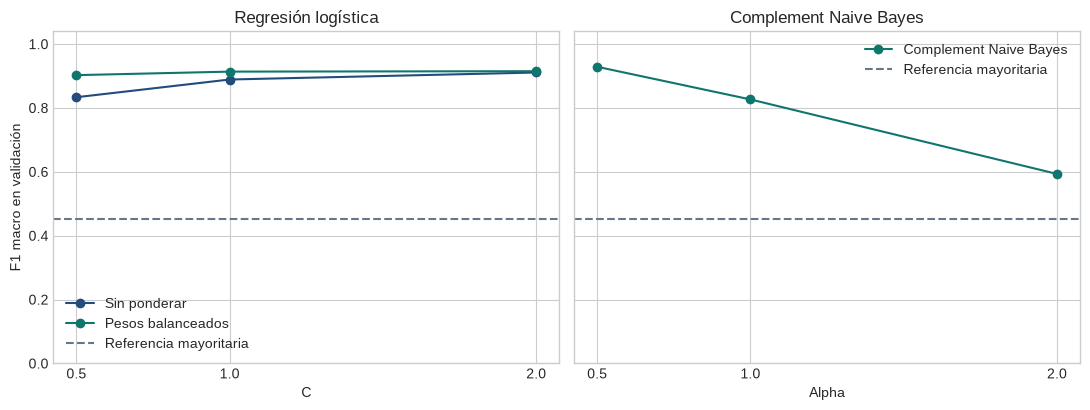

In [7]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
referencia = resultados[0]["metricas"]["f1_macro"]
for peso, etiqueta, color in [(None, "Sin ponderar", AZUL), ("balanced", "Pesos balanceados", TURQUESA)]:
    puntos = [(r["parametros"]["clasificador__C"], r["metricas"]["f1_macro"])
              for r in resultados if r["modelo"] == "logistica" and r["parametros"]["clasificador__class_weight"] == peso]
    ejes[0].plot(*zip(*sorted(puntos)), marker="o", color=color, label=etiqueta)
puntos_nb = [(r["parametros"]["clasificador__alpha"], r["metricas"]["f1_macro"])
             for r in resultados if r["modelo"] == "naive_bayes"]
ejes[1].plot(*zip(*sorted(puntos_nb)), marker="o", color=TURQUESA, label="Complement Naive Bayes")
for eje in ejes:
    eje.axhline(referencia, color=GRIS, linestyle="--", label="Referencia mayoritaria")
    eje.legend(loc="best")
    eje.set_ylim(0, 1.04)
ejes[0].set(title="Regresión logística", xlabel="C", ylabel="F1 macro en validación")
ejes[1].set(title="Complement Naive Bayes", xlabel="Alpha")
ejes[0].set_xticks(sorted(set(C_LOGISTICA)))
ejes[1].set_xticks(sorted(set(ALPHA_NAIVE_BAYES)))
mostrar_figura(fig, "02_parametros_en_validacion")

## 6. Evaluar en la prueba reservada

Se mide solo el candidato elegido. Las filas de la matriz representan la etiqueta real y las columnas la predicción. Revisamos especialmente las reseñas negativas clasificadas como positivas porque son posibles quejas que el administrador no encontraría con el filtro.

,precision,recall,f1-score,support
Negativa,0.922438,0.812195,0.863813,410.0
Positiva,0.960634,0.985317,0.972819,1907.0


F1 macro: 0.9183 · Exactitud: 95.5%


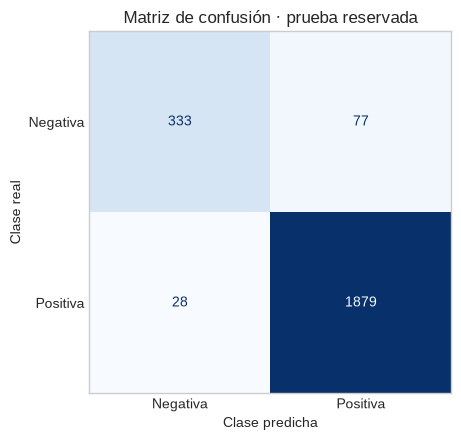

In [8]:
if EVALUAR_PRUEBA:
    prueba = conjuntos["prueba"]
    metricas_prueba, predicciones = evaluar(modelo_elegido, prueba)
    display(pd.DataFrame({"Negativa": metricas_prueba["negativa"], "Positiva": metricas_prueba["positiva"]}).T)
    print(f'F1 macro: {metricas_prueba["f1_macro"]:.4f} · Exactitud: {metricas_prueba["exactitud"]:.1%}')
    fig, ax = plt.subplots(figsize=(6, 4.5))
    matriz = np.asarray(metricas_prueba["matriz_confusion"])
    ConfusionMatrixDisplay(matriz, display_labels=["Negativa", "Positiva"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.grid(False)
    ax.set(title="Matriz de confusión · prueba reservada", xlabel="Clase predicha", ylabel="Clase real")
    mostrar_figura(fig, "03_matriz_de_confusion")

## 7. Validación cruzada complementaria y SVM lineal

Se rotan cinco pliegues **solo dentro de entrenamiento**. En cada rotación se vuelve a ajustar TF-IDF y se evalúan los dos modelos sobre el mismo pliegue. Es una comparación exploratoria ligada a los ejercicios de clase. La selección de la aplicación corresponde al protocolo de las secciones 5 y 6.

modelo_de_la_aplicacion: F1 macro medio 0.9063
svm_lineal: F1 macro medio 0.9395


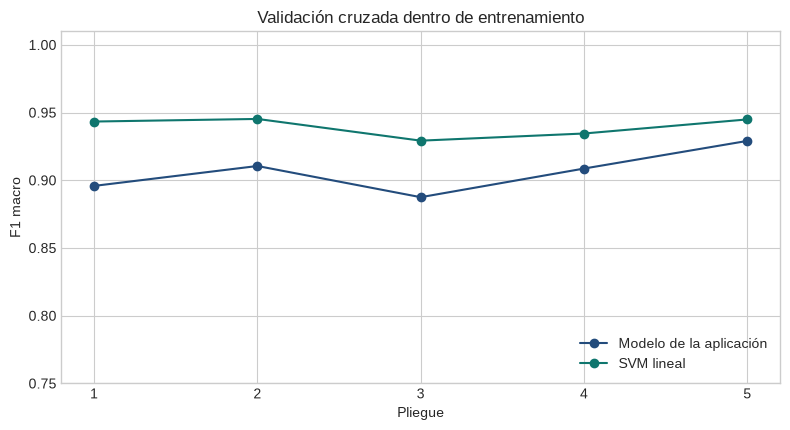

In [9]:
def revisar_modelos(filas, grupos_por_id, elegido):
    textos = [fila["review_text"] for fila in filas]
    etiquetas = [int(fila["label"]) for fila in filas]
    grupos = [grupos_por_id[fila["id"]] for fila in filas]

    modelos = {
        "modelo_de_la_aplicacion": construir_modelo(elegido["modelo"], **elegido["parametros"]),
        "svm_lineal": construir_modelo().set_params(
            clasificador=LinearSVC(C=1.0, class_weight="balanced", max_iter=5000, random_state=SEMILLA)
        ),
    }
    resultados = {nombre: [] for nombre in modelos}
    folds = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
    for numero, (ajuste, evaluacion) in enumerate(folds.split(textos, etiquetas, grupos), start=1):
        if {grupos[i] for i in ajuste} & {grupos[i] for i in evaluacion}:
            raise RuntimeError(f"Se repiten grupos entre ajuste y evaluación en el pliegue {numero}")
        for nombre, pipeline in modelos.items():
            modelo = clone(pipeline).fit([textos[i] for i in ajuste], [etiquetas[i] for i in ajuste])
            metricas, _ = evaluar(modelo, [filas[i] for i in evaluacion])
            resultados[nombre].append({
                "pliegue": numero,
                "n_ajuste": len(ajuste),
                "n_evaluacion": len(evaluacion),
                "f1_macro": metricas["f1_macro"],
                "exactitud": metricas["exactitud"],
                "recall_negativas": metricas["negativa"]["recall"],
            })

    resumen = {}
    for nombre, pliegues in resultados.items():
        resumen[nombre] = {
            campo: {
                "media": mean(pliegue[campo] for pliegue in pliegues),
                "desviacion_estandar_muestral": stdev(pliegue[campo] for pliegue in pliegues),
            }
            for campo in ("f1_macro", "exactitud", "recall_negativas")
        }
        print(f'{nombre}: F1 macro medio {resumen[nombre]["f1_macro"]["media"]:.4f}')
    ruta = RESULTADOS / "revision_materia.json"
    escribir_json(ruta, {
        "alcance": "Comparación exploratoria posterior a la selección original, solo sobre entrenamiento",
        "scikit_learn": version("scikit-learn"),
        "n_entrenamiento": len(filas),
        "sha256_particiones": particiones["sha256_particiones"],
        "metodo": "StratifiedGroupKFold, 5 pliegues y semilla 42. Pipeline ajustado por pliegue.",
        "configuraciones": {
            "modelo_de_la_aplicacion": {"modelo": elegido["modelo"], "parametros": elegido["parametros"]},
            "svm_lineal": {"modelo": "LinearSVC", "parametros": modelos["svm_lineal"]["clasificador"].get_params()},
        },
        "resultados_por_pliegue": resultados,
        "resumen": resumen,
    })
    return resultados, resumen

pliegues, resumen_cv = revisar_modelos(conjuntos["entrenamiento"],
    {identificador: fila["grupo"] for identificador, fila in por_id.items()}, elegido)
fig, ax = plt.subplots(figsize=(8, 4.4))
for nombre, etiqueta, color in [("modelo_de_la_aplicacion", "Modelo de la aplicación", AZUL),
                               ("svm_lineal", "SVM lineal", TURQUESA)]:
    ax.plot([fila["pliegue"] for fila in pliegues[nombre]],
            [fila["f1_macro"] for fila in pliegues[nombre]], marker="o", label=etiqueta, color=color)
ax.set(title="Validación cruzada dentro de entrenamiento", xlabel="Pliegue", ylabel="F1 macro", ylim=(0.75, 1.01))
ax.set_xticks(range(1, 6))
ax.legend(loc="lower right")
mostrar_figura(fig, "04_validacion_cruzada")

## 8. Exportar el modelo y comprobar su recarga

El archivo `sentimiento.joblib` reúne TF-IDF y el clasificador ajustado. El backend lo consume junto a `metricas.json`, que registra su huella y el protocolo. La exportación conserva las etiquetas internas y verifica que el pipeline recargado produzca las mismas predicciones. `errores_prueba.json` registra identificadores y clases para revisar errores sin copiar el texto de los comentarios.

In [10]:
if EVALUAR_PRUEBA and EXPORTAR_MODELO:
    errores = [
        {"id": fila["id"], "etiqueta": int(fila["label"]), "prediccion": int(prediccion)}
        for fila, prediccion in zip(prueba, predicciones, strict=True)
        if int(fila["label"]) != prediccion
    ]
    DESTINO_MODELO.mkdir(parents=True, exist_ok=True)
    with tempfile.TemporaryDirectory(dir=DESTINO_MODELO.parent, prefix=".modelo-") as directorio:
        temporal = Path(directorio)
        pipeline = temporal / "sentimiento.joblib"
        joblib.dump(modelo_elegido, pipeline, compress=3)
        recargado = joblib.load(pipeline)
        np.testing.assert_array_equal(recargado.predict([fila["review_text"] for fila in prueba]), predicciones)
        escribir_json(temporal / "errores_prueba.json", errores)
        escribir_json(temporal / "metricas.json", {
            "versiones": {paquete: version(paquete) for paquete in ["scikit-learn", "numpy", "joblib"]},
            "semilla_particiones": particiones["semilla"],
            "sha256_dataset": particiones["sha256_dataset"],
            "sha256_particiones": particiones["sha256_particiones"],
            "seleccion": "F1 macro de validación, luego recall negativo, luego orden de evaluación",
            "ajuste_pipeline": "Solo entrenamiento",
            "labels_matriz": {"0": "negativa", "1": "positiva"},
            "ejes_matriz": "Filas reales, columnas predichas, orden 0 y 1",
            "comparacion_validacion": resultados,
            "elegido_validacion": elegido,
            "evaluacion_prueba": metricas_prueba,
            "pipeline": {"archivo": pipeline.name, "sha256": sha256(pipeline)},
        })
        for nombre in ("sentimiento.joblib", "errores_prueba.json", "metricas.json"):
            (temporal / nombre).replace(DESTINO_MODELO / nombre)
    print(f"Pipeline recargado y verificado. Exportación: {DESTINO_MODELO.relative_to(BASE)}")

Pipeline recargado y verificado. Exportación: resultados/modelo


## 9. Explorar grupos de quejas para apoyar decisiones

Después de la clasificación binaria, la aplicación agrupa las reseñas negativas del archivo cargado mediante **TF-IDF y K-means**. Se ajusta una representación independiente para ese archivo; el clasificador de sentimiento y sus métricas se conservan. Esta sección utiliza la misma función del backend para reproducir su comportamiento.

Como exploración se agrupan las reseñas con etiqueta negativa de **entrenamiento**, sin consultar la prueba reservada. La interfaz trabaja con las negativas **predichas**, que pueden contener errores de clasificación. Se eliminan palabras funcionales españolas únicamente para descubrir temas. Se consideran palabras de al menos tres letras y hasta 5.000 términos. La semilla es 42 y se realizan diez inicializaciones. La cantidad de grupos sigue una regla exploratoria: el mínimo entre cinco, los vectores distintos y la raíz de la mitad de las filas utilizables, redondeada hacia arriba. No se interpreta como un número óptimo validado.

Cada fila pertenece a un grupo; los textos sin términos utilizables se conservan en un grupo aparte. Los tres términos de mayor peso medio identifican cada grupo. **Los nombres describen vocabulario compartido, no categorías operativas validadas ni causas demostradas.** Un comentario puede hablar de varios asuntos y el volumen no mide gravedad. Los grupos y sus identificadores son locales al archivo; revisar los comentarios antes de priorizar acciones.

Este paso aplica el aprendizaje no supervisado visto en clase y permite explorar asuntos repetidos, conservar la trazabilidad de cada reseña y exportar comentarios agrupados. Referencia técnica: [agrupación de documentos con K-means, scikit-learn](https://scikit-learn.org/stable/auto_examples/text/plot_document_clustering.html).

,Grupo,Palabras representativas,Reseñas
0,1,habitación · noche · recepción,332
1,2,habitaciones · estrellas · mal,305
2,3,baño · habitación · cama,257
3,4,servicio · comida · hora,217
4,5,reserva · booking · día,118


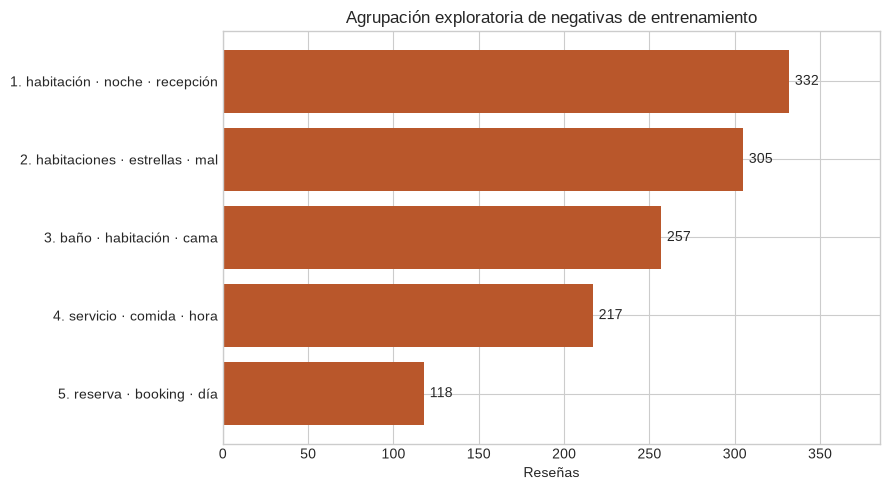

In [11]:
from backend import LoteNegativas, agrupar_negativas

negativas_exploracion = [fila for fila in conjuntos["entrenamiento"] if fila["label"] == "0"]
agrupacion = agrupar_negativas(LoteNegativas(resenas=[
    {"numero": i, "texto": fila["review_text"]}
    for i, fila in enumerate(negativas_exploracion, 1)
]))
assert sum(grupo.cantidad for grupo in agrupacion.grupos) == len(negativas_exploracion)
assert sorted(numero for grupo in agrupacion.grupos for numero in grupo.resenas) == list(
    range(1, len(negativas_exploracion) + 1)
)
resumen_temas = pd.DataFrame([
    {"Grupo": grupo.id, "Palabras representativas": grupo.tema, "Reseñas": grupo.cantidad}
    for grupo in agrupacion.grupos
])
display(resumen_temas)
fig, eje = plt.subplots(figsize=(9, 5))
barras = eje.barh(
    [f"{grupo.id}. {grupo.tema}" for grupo in agrupacion.grupos],
    [grupo.cantidad for grupo in agrupacion.grupos], color=NARANJA,
)
eje.bar_label(barras, padding=4)
eje.invert_yaxis()
eje.set(title="Agrupación exploratoria de negativas de entrenamiento", xlabel="Reseñas")
eje.set_xlim(0, max(grupo.cantidad for grupo in agrupacion.grupos) * 1.16)
mostrar_figura(fig, "05_grupos_de_quejas")
escribir_json(RESULTADOS / "agrupacion_exploratoria.json", {
    "origen": "etiquetas negativas del conjunto de entrenamiento",
    "total": agrupacion.total,
    "grupos": [{**grupo.model_dump(), "ids_corpus": [
        negativas_exploracion[numero - 1]["id"] for numero in grupo.resenas
    ]} for grupo in agrupacion.grupos],
})

## Lectura de resultados

La selección en **validación** favoreció TF-IDF con Complement Naive Bayes y suavizado de 0,5. En la **prueba reservada** obtuvo F1 macro de **0,9183** y detectó **333 de 410 reseñas negativas**. F1 macro asigna el mismo peso a cada clase, relevante ante el desbalance del corpus.

La **validación cruzada interna**, realizada solo sobre entrenamiento, favoreció a la SVM lineal. Sus promedios corresponden a un protocolo distinto de la prueba reservada. La agrupación organiza vocabulario compartido entre las negativas y conserva su trazabilidad, sin establecer categorías temáticas validadas ni gravedad.

El desempeño mide la concordancia con etiquetas derivadas de estrellas en AHR. Las valoraciones mixtas y los cambios de idioma o región limitan la interpretación de la evidencia. Las clasificaciones y los grupos apoyan la revisión humana de los comentarios.
